# Чекпойнт 2. Бананы и кабачки

Задача чекпойнта №2:

Исследовать собранные фотографии с помощью EDA, оценить состав и качество данных, отобрать подходящие изображения, убрать точные и похожие дубликаты с помощью MD5, pHash и признаков ResNet18 (пока классификационного слоя), а затем обучить первый baseline и получить начальную оценку качества.

Мы разделили датасет на 3 части данных, что бы ускорить процесс обучения и дать возможность каждому поработаь с данными.

Моя часть данных — фотографии бананов и кабачков. Посмотрю, что получилось собрать,
уберу повторы и обучу первый baseline на ResNet18.

План был взять по 500 хороших, 1 000 плохих и 100 мусорных фото на каждый товар.
Кабачки удвлось собраны не полностью, поэтому использую то, что есть.
Мусор для них беру из бананов — это +/- одни и те же фотографии (позже дополню данные)

## Подготовка


In [1]:
from pathlib import Path
from itertools import combinations
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import imagehash
from IPython.display import display

In [ ]:
DATA_ROOT = Path.home() / 'Desktop' / 'Годовой проект - 2 chekpoint'
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.max_colwidth', 80)

FRUITS = ['Бананы', 'Кабачки']
LABELS = ['Хорошие', 'Плохие', 'Мусор']
LABEL_MAP = {'Хорошие': 'Хорошие', 'Плохие': 'Плохие',
             'Полохие': 'Плохие', 'Мусор': 'Мусор'}  # В папке бананов есть опечатка.
EXTENSIONS = {'.jpg', '.jpeg', '.png'}
TARGET = pd.Series({'Хорошие': 500, 'Плохие': 1000, 'Мусор': 100})

## Какие данные есть
Соберу таблицу с меткой, размером и хешами каждого фото. Заодно перепроверю,
все ли изображения открываются и нет ли среди них других файлов.

In [ ]:
files = sorted(p for fruit in FRUITS for p in (DATA_ROOT / fruit).rglob('*')
               if p.is_file() and not any(part.startswith('.')
                                        for part in p.relative_to(DATA_ROOT).parts))

In [4]:
def inspect_image(path):
    relative = path.relative_to(DATA_ROOT)
    row = {'path': str(relative), 'fruit': relative.parts[0],
           'label': LABEL_MAP.get(relative.parts[1]), 'error': None}
    if path.suffix.lower() not in EXTENSIONS:
        row['error'] = 'Не изображение: ' + path.suffix
        return row
    try:
        row.update(bytes=path.stat().st_size,
                   md5=hashlib.md5(path.read_bytes()).hexdigest())
        with Image.open(path) as image:
            image.load()  # Проверка чтения всего файла, а не только заголовка.
            row.update(format=image.format, mode=image.mode)
            rgb = ImageOps.exif_transpose(image).convert('RGB')
            row.update(width=rgb.width, height=rgb.height,
                       phash=str(imagehash.phash(rgb, hash_size=8)))
    except Exception as error:
        row['error'] = f'{type(error).__name__}: {error}'
    return row

In [5]:
inventory = pd.DataFrame([inspect_image(path) for path in files])
excluded = inventory[inventory.error.notna()].copy()
images = inventory[inventory.error.isna()].copy().reset_index(drop=True)
images[['width', 'height', 'bytes']] = images[['width', 'height', 'bytes']].astype(int)
images['megapixels'] = images.width * images.height / 1_000_000
images['aspect_ratio'] = images.width / images.height
images['short_side'] = images[['width', 'height']].min(axis=1)
print(f'Файлов: {len(inventory)}; читаемых изображений: {len(images)}; исключено: {len(excluded)}')
display(excluded[['path', 'error']])

Файлов: 2604; читаемых изображений: 2599; исключено: 5


,path,error
1641,Кабачки/Плохие/38321602-AC4BD1AFD80E43459A2.textClipping,Не изображение: .textClipping
2282,Кабачки/Плохие/кабачки.textClipping,Не изображение: .textClipping
2390,Кабачки/Хорошие/38972544-B6E53D6F905246D1B76.textClipping,Не изображение: .textClipping
2400,Кабачки/Хорошие/39004056-08BE20B0C7784E80B1A.textClipping,Не изображение: .textClipping
2541,Кабачки/Хорошие/Terminal№2Time.2026.6.8.20.4.textClipping,Не изображение: .textClipping


In [6]:
def count_table(frame):
    return (pd.crosstab(frame.fruit, frame.label)
            .reindex(index=FRUITS, columns=LABELS, fill_value=0))

In [7]:
print('Физически имеющиеся изображения:')
display(count_table(images))

Физически имеющиеся изображения:


label,Хорошие,Плохие,Мусор
fruit,,,
Бананы,500,1000,100
Кабачки,302,697,0


In [ ]:
def with_shared_junk(frame):
    original = frame.assign(shared=False, source_fruit=frame.fruit)
    shared = frame[(frame.fruit == 'Бананы') & (frame.label == 'Мусор')].copy()
    shared = shared.assign(fruit='Кабачки', shared=True, source_fruit='Бананы')
    return pd.concat([original, shared], ignore_index=True)

In [9]:
views = with_shared_junk(images)
print('Логические записи с общим мусором для кабачков:')
display(count_table(views))
print(f'Записей: {len(views)}; исходных путей: {views.path.nunique()}')

Логические записи с общим мусором для кабачков:


label,Хорошие,Плохие,Мусор
fruit,,,
Бананы,500,1000,100
Кабачки,302,697,100


Записей: 2699; исходных путей: 2599


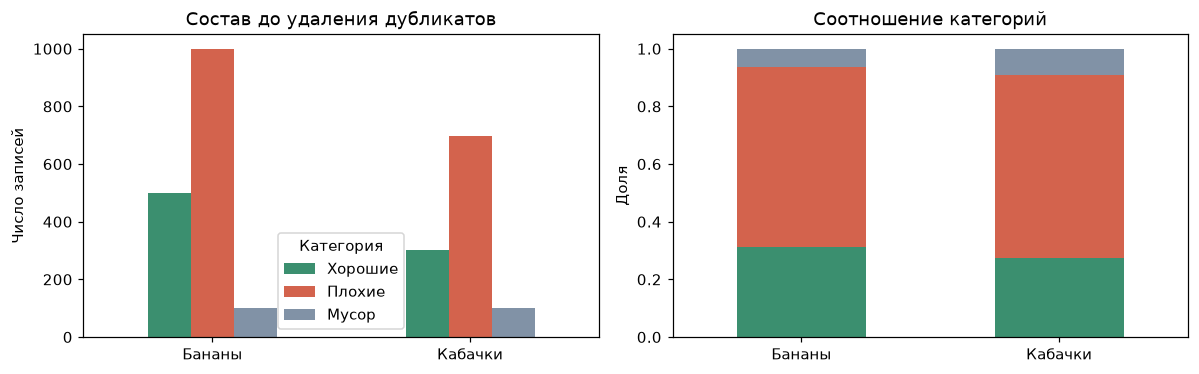

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
count_table(views).plot.bar(ax=axes[0], rot=0, color=['#3B8F6F', '#D3634D', '#8192A6'])
axes[0].set(xlabel='', ylabel='Число записей', title='Состав до удаления дубликатов')
axes[0].legend(title='Категория')
count_table(views).div(count_table(views).sum(axis=1), axis=0).plot.bar(
    ax=axes[1], stacked=True, rot=0, color=['#3B8F6F', '#D3634D', '#8192A6'])
axes[1].set(xlabel='', ylabel='Доля', title='Соотношение категорий')
axes[1].legend().remove()
plt.tight_layout()
plt.show()

Бананов до очистки ровно столько, сколько планировали с командой при дизайне задачи. 
Кабачков — 302 хороших и 697 плохих (просто не успел все сделать - разметку делали своими силами).
В папке с кабачками ещё были пять файлов `.textClipping`, их не беру.
Все 2 599 изображения открылись.

Плохих фото заметно больше хороших, а мусора меньше всего. То есть классы несбалансированы.
После добавления общего мусора получилось 2 699 записей, но отдельных файлов по-прежнему 2 599.

## Размеры и примеры фотографий

In [11]:
display(images.groupby(['fruit', 'label']).agg(
    count=('path', 'size'), min_width=('width', 'min'), min_height=('height', 'min'),
    median_width=('width', 'median'), median_height=('height', 'median'),
    median_mp=('megapixels', 'median'), min_short_side=('short_side', 'min')).round(2))
display(pd.crosstab([images.fruit, images.label], images['format']))
display(images['mode'].value_counts().rename('Количество').to_frame())

count  min_width  min_height  median_width  median_height  \
fruit   label                                                                
Бананы  Мусор      100        382         480        1920.0         2560.0   
        Плохие    1000        288         368        1920.0         2560.0   
        Хорошие    500        382         480        1920.0         2560.0   
Кабачки Плохие     697        300         300        1920.0         2560.0   
        Хорошие    302        384         512        1920.0         2560.0   

                 median_mp  min_short_side  
fruit   label                               
Бананы  Мусор         4.92             382  
        Плохие        4.92             288  
        Хорошие       4.92             382  
Кабачки Плохие        4.92             300  
        Хорошие       4.92             384

format           JPEG  MPO  PNG
fruit   label                  
Бананы  Мусор     100    0    0
        Плохие    990    1    9
        Хорошие   500    0    0
Кабачки Плохие    697    0    0
        Хорошие   302    0    0

,Количество
mode,
RGB,2598
RGBA,1


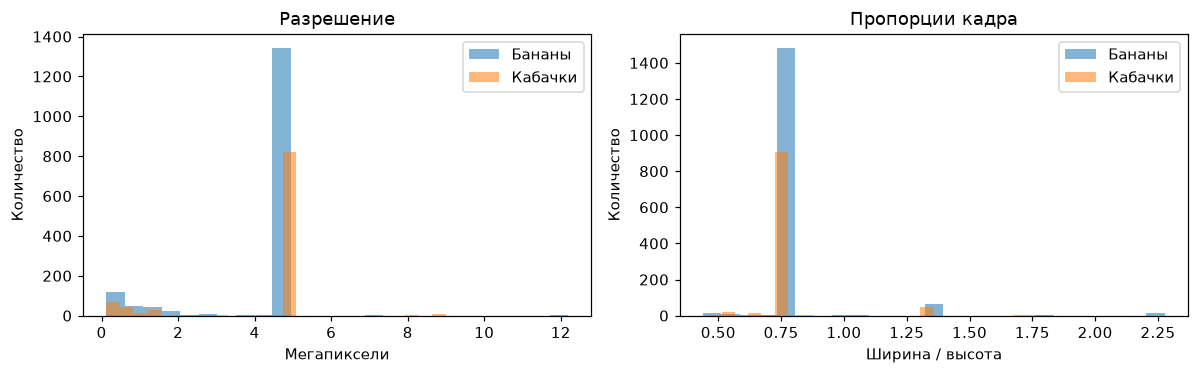

Изображений с короткой стороной меньше 224 пикселей: 0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for fruit in FRUITS:
    subset = images[images.fruit == fruit]
    axes[0].hist(subset.megapixels, bins=25, alpha=0.55, label=fruit)
    axes[1].hist(subset.aspect_ratio, bins=25, alpha=0.55, label=fruit)
axes[0].set(xlabel='Мегапиксели', ylabel='Количество', title='Разрешение')
axes[1].set(xlabel='Ширина / высота', ylabel='Количество', title='Пропорции кадра')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
print('Изображений с короткой стороной меньше 224 пикселей:', (images.short_side < 224).sum())

In [13]:
def show_images(paths, titles, columns=4, figsize=None):
    rows = (len(paths) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns,
                             figsize=figsize or (3 * columns, 2.7 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, path, title in zip(axes.ravel(), paths, titles):
        with Image.open(DATA_ROOT / path) as image:
            preview = ImageOps.exif_transpose(image).convert('RGB')
            preview.thumbnail((420, 420))
            ax.imshow(preview)
        ax.set_title(title, fontsize=9)
    plt.tight_layout()
    plt.show()

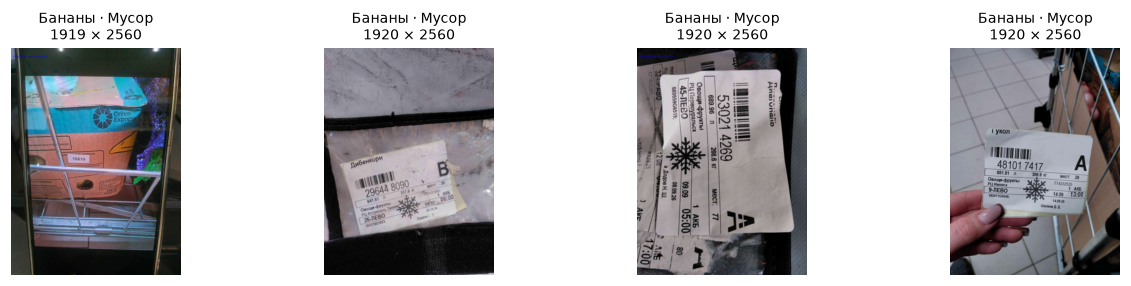

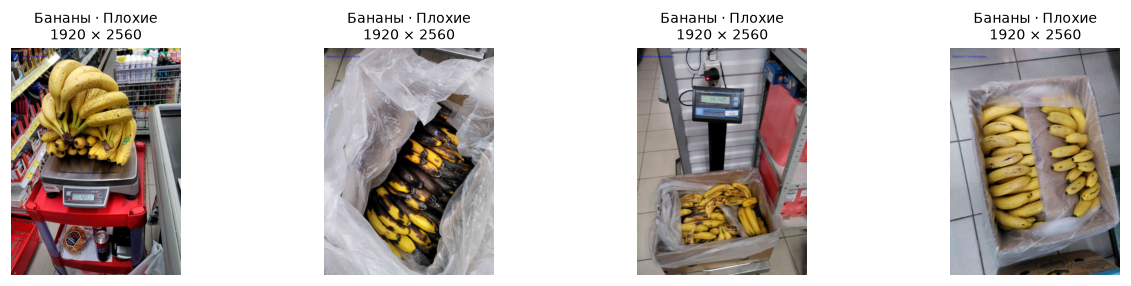

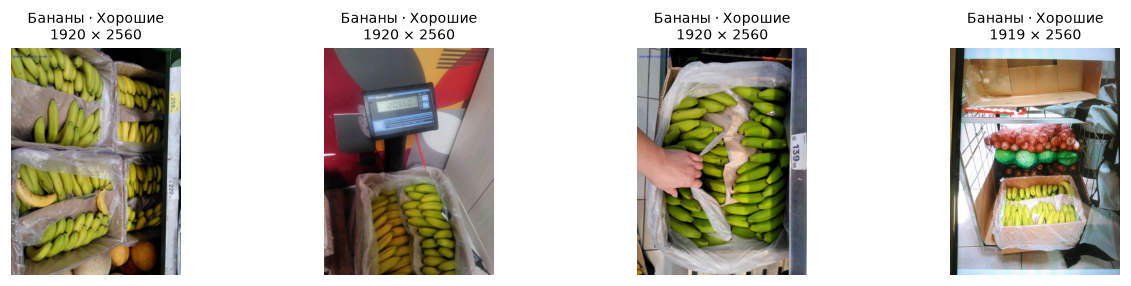

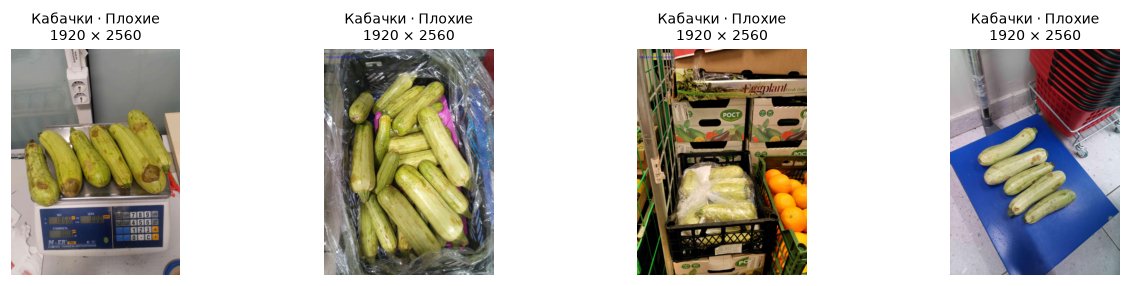

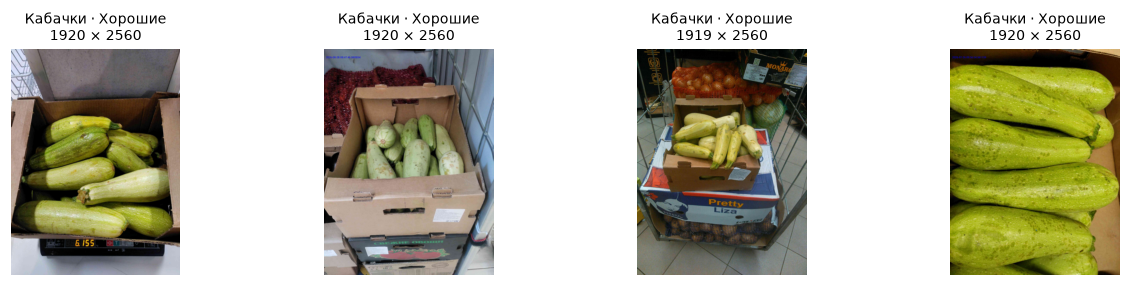

In [14]:
for (fruit, label), subset in images.groupby(['fruit', 'label'], sort=True):
    sample = subset.sample(min(4, len(subset)), random_state=SEED)
    show_images(sample.path.tolist(),
                [f'{fruit} · {label}\n{r.width} × {r.height}' for r in sample.itertuples()])

Чаще всего размер фото — 1 920 × 2 560. Есть и небольшие кадры, но короткая сторона
у всех не меньше 224 пикселей. Почти всё в JPEG, ещё есть 9 PNG и один MPO
(для него читается первый кадр). При обработке привожу изображения к RGB.

По примерам видно, что условия съёмки разные: крупный план, коробка целиком, товар на весах.
У плохих бананов встречается потемневшая кожица, у кабачков — повреждённые участки.
При этом по одному цвету качество не определить. Плёнка, освещение и дальний план тоже мешают.
Мусор — в основном этикетки и закрытая упаковка.

## Точные копии: MD5
Проведу проверку на копии с пмоощью MD5, отдельно посмотрю, не попало ли одно фото в разные категории.

In [15]:
md5_groups = images.groupby('md5').agg(
    files=('path', 'size'), fruits=('fruit', 'nunique'), labels=('label', 'nunique'))
conflict_hashes = md5_groups.index[(md5_groups.fruits > 1) | (md5_groups.labels > 1)]
exact_duplicates = images[images.duplicated('md5', keep=False)].sort_values(['md5', 'path'])
print('Групп одинаковых файлов:', int((md5_groups.files > 1).sum()))
print('Лишних точных копий:', len(images) - images.md5.nunique())
print('Групп с противоречивой разметкой:', len(conflict_hashes))
display(exact_duplicates[['fruit', 'label', 'path', 'md5']].head(12))

unique = (images.sort_values('path').drop_duplicates('md5')
          .reset_index(drop=True))

Групп одинаковых файлов: 20
Лишних точных копий: 22
Групп с противоречивой разметкой: 1


,fruit,label,path,md5
1600,Кабачки,Плохие,Кабачки/Плохие/01.jpg,026cb6a1fcae45328ae56a5b3d431d93
1603,Кабачки,Плохие,Кабачки/Плохие/03.jpg,026cb6a1fcae45328ae56a5b3d431d93
1610,Кабачки,Плохие,Кабачки/Плохие/08.jpg,026cb6a1fcae45328ae56a5b3d431d93
1085,Бананы,Плохие,Бананы/Полохие/бан3.jpg,02f4906b6a3eafa6094cf4fd02e04540
1086,Бананы,Плохие,Бананы/Полохие/бан7.jpg,02f4906b6a3eafa6094cf4fd02e04540
1613,Кабачки,Плохие,Кабачки/Плохие/10 2.jpg,1344aeb4a156fc7f717afce1b5659cee
1615,Кабачки,Плохие,Кабачки/Плохие/10.jpg,1344aeb4a156fc7f717afce1b5659cee
1477,Бананы,Хорошие,Бананы/Хорошие/Terminal№2Time.2026.8.3.16.49.9 — копия.jpeg,1db2f586e0ac0ab0e5a643ee7b5c4a10
1478,Бананы,Хорошие,Бананы/Хорошие/Terminal№2Time.2026.8.3.16.49.9.jpeg,1db2f586e0ac0ab0e5a643ee7b5c4a10
2136,Кабачки,Плохие,Кабачки/Плохие/Terminal№2Time.2026.5.4.18.9.25 — копия.jpeg,1f1e31d997150e351be349eff9263989


,fruit,label,path
978,Бананы,Плохие,Бананы/Полохие/Terminal№42Time.2026.3.28.13.22.29.jpeg
1527,Бананы,Хорошие,Бананы/Хорошие/Terminal№42Time.2026.3.28.13.22.29.jpeg


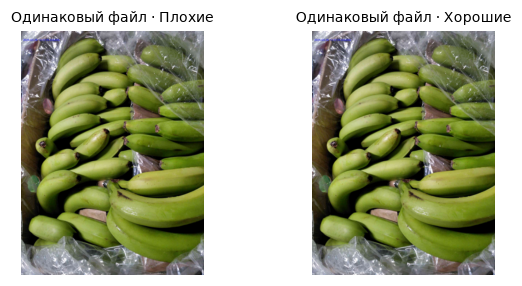

In [16]:
conflicts = images[images.md5.isin(conflict_hashes)]
display(conflicts[['fruit', 'label', 'path']])
if len(conflicts):
    show_images(conflicts.path.tolist(),
                [f'Одинаковый файл · {r.label}' for r in conflicts.itertuples()], columns=2)

Нашлось 20 групп одинаковых файлов, всего 22 лишние копии.
Одно фото бананов лежит и в хороших, и в плохих. Пока уберу обе записи этой пары:
без уточнения разметки непонятно, какой ответ на ней должна учить модель. 

## Похожие фотографии: pHash
MD5 не найдёт фото, которое пересохранили с другим сжатием. Для таких случаев попробую pHash.
У него сравнивается число отличающихся битов: чем меньше расстояние, тем больше похожи кадры.
Сравню пороги 1 и 2 и посмотрю найденные пары.

In [17]:
hashes = [int(value, 16) for value in unique.phash]
pair_rows = []
for i, j in combinations(range(len(unique)), 2):
    distance = (hashes[i] ^ hashes[j]).bit_count()
    if distance <= 2:
        pair_rows.append({'i': i, 'j': j, 'distance': distance,
                          'same_label': unique.loc[i, 'label'] == unique.loc[j, 'label'],
                          'same_fruit': unique.loc[i, 'fruit'] == unique.loc[j, 'fruit']})
pairs = pd.DataFrame(pair_rows, columns=['i', 'j', 'distance', 'same_label', 'same_fruit'])
display(pd.DataFrame([
    {'Порог': threshold, 'Пар': int((pairs.distance <= threshold).sum()),
     'Пар с разными метками': int(((pairs.distance <= threshold)
                                  & ~(pairs.same_label & pairs.same_fruit)).sum())}
    for threshold in [1, 2]]))
display(pairs)

,Порог,Пар,Пар с разными метками
0,1,0,0
1,2,1,0


,i,j,distance,same_label,same_fruit
0,1093,1363,2,True,True


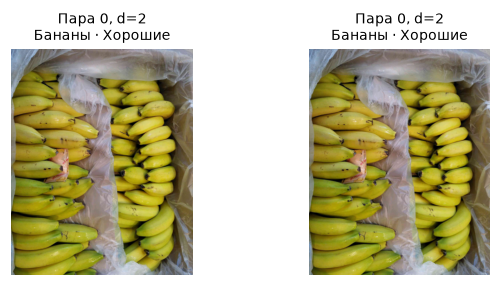

In [18]:
# Все найденные пары с расстоянием <= 2, а не только самые удачные примеры.
for offset in range(0, len(pairs), 6):
    paths, titles = [], []
    for pair_id, pair in pairs.iloc[offset:offset+6].iterrows():
        for side in ['i', 'j']:
            row = unique.loc[int(pair[side])]
            paths.append(row.path)
            titles.append(f'Пара {pair_id}, d={pair.distance}\n{row.fruit} · {row.label}')
    show_images(paths, titles, columns=min(4, len(paths)))

С порогом 1 после MD5 ничего не нашлось. С порогом 2 — одна пара хороших бананов:
`3 2.jpeg` и `6.jpeg`. На них совпадают коробка, плёнка и расположение бананов.
Оставлю один кадр. Для этой подборки беру порог 2; на остальных товарах его ещё нужно посмотреть.

## Сходство через ResNet18
Здесь использую ResNet18 **без классификационного слоя** (как договаривались с проверяющим).
Строка `model.fc = nn.Identity()` убирает последний слой. Вместо ответа «какой это класс»
модель выдаёт 512 чисел — признаки изображения. По ним считаю косинусное сходство.

In [19]:
import torch
from torch import nn
from torchvision.models import resnet18, ResNet18_Weights

torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()
model = resnet18(weights=weights, progress=False)
model.fc = nn.Identity()  # На выходе 512 признаков вместо классов ImageNet.
model = model.to(device).eval()

In [20]:
features = []
batch_size = 32
with torch.inference_mode():
    for start in range(0, len(unique), batch_size):
        batch = []
        for path in unique.path.iloc[start:start+batch_size]:
            with Image.open(DATA_ROOT / path) as image:
                rgb = ImageOps.exif_transpose(image).convert('RGB')
                batch.append(preprocess(rgb))
        output = model(torch.stack(batch).to(device))
        features.append(nn.functional.normalize(output, dim=1).cpu().numpy())
embeddings = np.concatenate(features)
similarity = embeddings @ embeddings.T
print('Устройство:', device)
print('Веса:', weights)
print('Матрица признаков:', embeddings.shape)

Устройство: mps
Веса: ResNet18_Weights.IMAGENET1K_V1
Матрица признаков: (2577, 512)


In [21]:
left, right = np.triu_indices(len(unique), k=1)
scores = similarity[left, right]
known_pairs = {(int(r.i), int(r.j)) for r in pairs.itertuples()}
top_pairs = []
for position in np.argsort(scores)[::-1]:
    i, j = int(left[position]), int(right[position])
    if (i, j) in known_pairs:
        continue
    top_pairs.append({'i': i, 'j': j, 'cosine': float(scores[position]),
                      'phash_distance': (hashes[i] ^ hashes[j]).bit_count()})
    if len(top_pairs) == 5:
        break
cosine_pairs = pd.DataFrame(top_pairs)
display(cosine_pairs.round(4))

,i,j,cosine,phash_distance
0,1826,1827,0.9965,4
1,2479,2480,0.9930,4
2,594,595,0.9876,6
3,1814,1817,0.9810,20
4,1225,1226,0.9784,16


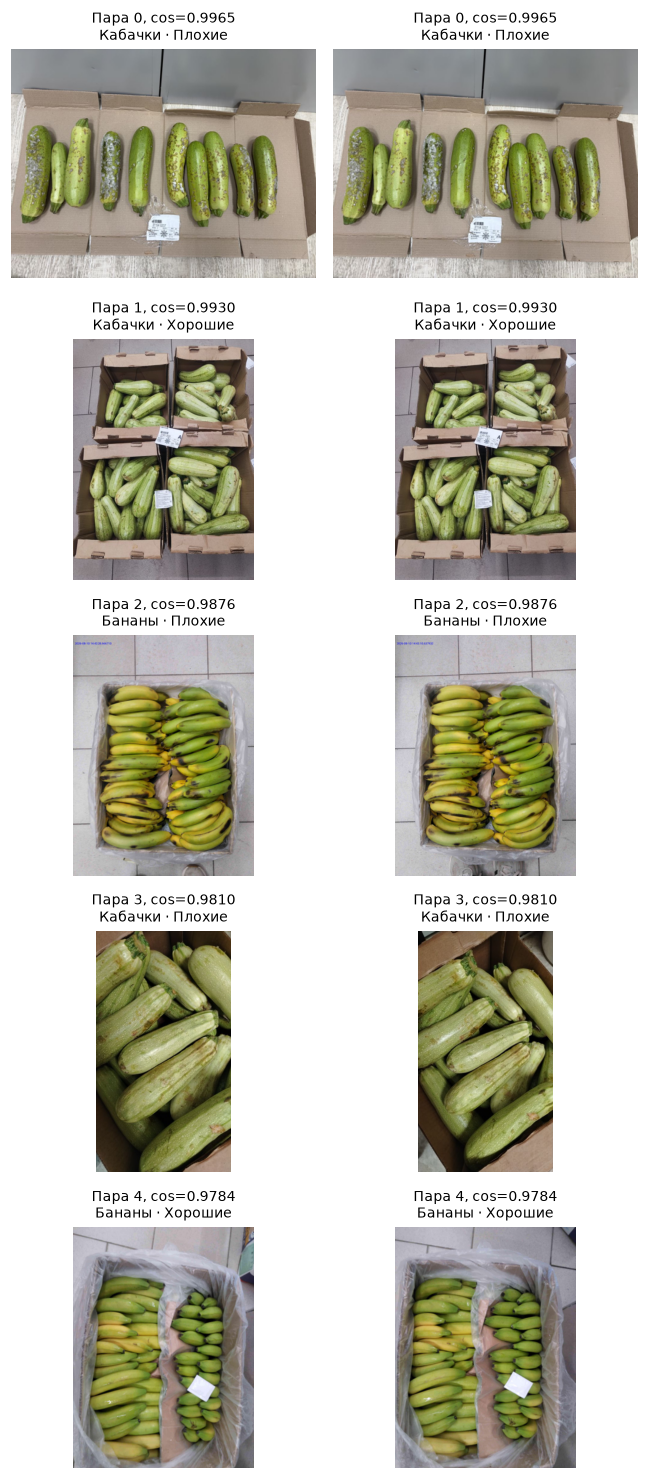

In [22]:
paths, titles = [], []
for pair_id, pair in cosine_pairs.iterrows():
    for side in ['i', 'j']:
        row = unique.loc[int(pair[side])]
        paths.append(row.path)
        titles.append(f'Пара {pair_id}, cos={pair.cosine:.4f}\n{row.fruit} · {row.label}')
show_images(paths, titles, columns=2)

Взял пять самых похожих пар, которые не нашёл pHash. Сходство у них от 0,978 до 0,997,
но расстояние pHash уже от 4 до 20. На картинках повторяются те же коробки и раскладка товара,
иногда с немного другим ракурсом. Из каждой пары оставлю один кадр.
Это не значит, что любой высокий cosine дубликат.

## Что осталось после очистки
Из найденных пар убираю конкретные просмотренные фотографии. Их пути записал ниже,
чтобы было видно, что именно исключено. Исходные файлы на диске не удаляю.

In [ ]:
near_duplicates = [
    'Бананы/Полохие/Terminal№1Time.2026.8.10.14.43.10.jpeg',
    'Бананы/Хорошие/3 2.jpeg',
    'Бананы/Хорошие/39340632-72C141C017DF4697A57461719F3CA3EA-94.jpg',
    'Кабачки/Плохие/IMG_20250724_112659.jpg',
    'Кабачки/Плохие/IMG_2586.jpeg',
    'Кабачки/Хорошие/IMG-20260625-WA0048.jpg',
]

In [24]:
clean = unique[
    ~unique.md5.isin(conflict_hashes) & ~unique.path.isin(near_duplicates)
].copy()
selected = with_shared_junk(clean)

before = count_table(views)
after = count_table(selected)
summary = pd.DataFrame([
    {'Товар': fruit, 'Категория': label,
     'До': before.loc[fruit, label], 'После': after.loc[fruit, label],
     'Ориентир': TARGET[label]}
    for fruit in FRUITS for label in LABELS
])
display(summary)
print('Отдельных файлов:', len(clean))
print('Записей с общим мусором:', len(selected))

,Товар,Категория,До,После,Ориентир
0,Бананы,Хорошие,500,493,500
1,Бананы,Плохие,1000,988,1000
2,Бананы,Мусор,100,100,100
3,Кабачки,Хорошие,302,300,500
4,Кабачки,Плохие,697,689,1000
5,Кабачки,Мусор,100,100,100


Отдельных файлов: 2570
Записей с общим мусором: 2670


После очистки осталось 2 570 отдельных фото:
- бананы — 493 хороших, 988 плохих и 100 мусорных;
- кабачки — 300 хороших и 689 плохих. Для мусора используются те же 100 фото.

Для первого обучения возьму этот объём.

## Выводы по EDA

Главная проблема этой подборки оказалась не в повреждённых файлах, а в повторах и разметке.
Все 2 599 фотографий открылись. Пять файлов `.textClipping` к изображениям не относятся — их исключил.

**По бананам** данных получилось больше: после очистки осталось 493 хороших, 988 плохих и 100 мусорных фото.
На примерах плохих бананов заметны потемнения, но один цвет не определяет качество:
зелёные бананы встречаются и среди хороших. Поэтому простого правила по цвету здесь недостаточно.
(Позже узнал у специалистов если банан зеленый и влажный это хороший банан, если сухой - плохой)

**По кабачкам** осталось 300 хороших и 689 плохих фото. Эта часть заметно меньше банановой,
особенно категория хороших. На общих планах повреждения не всегда хорошо видны, иногда мешает плёнка (сохранял их специально).
Для первого baseline использую имеющиеся данные, но в дальнейшем в первую очередь стоит добрать хорошие кабачки.

**Классы несбалансированы:** плохих фотографий примерно вдвое больше хороших, а мусора меньше всего.
При обучении это нужно учитывать. Одной accuracy будет мало — модель может получать высокий результат
за счёт частых классов, поэтому буду смотреть ещё macro-F1 и ошибки по каждой категории.

**Дубликаты нашлись разными способами.** MD5 выявил точные копии, pHash с порогом 2 — ещё одну похожую пару,
а признаки ResNet18 помогли найти пять дополнительных пар с изменениями кадра или ракурса.
Одного MD5 оказалось недостаточно. При этом высокий cosine сам по себе не означает дубликат,
показанные пары я дополнительно посмотрел. Отдельная проблема — одно фото бананов с двумя противоположными
метками (обе его записи пока исключил)

**Условия съёмки сильно различаются.** Есть крупные планы, коробки и товар на весах.
Чаще всего размер — 1 920 × 2 560, но размеры и пропорции не у всех одинаковые.
Для модели приведу изображения к одному размеру. При этом фон, коробки и весы могут стать
подсказкой вместо состояния самого товара — это ограничение нашей подборки.

В итоге для обучения есть **2 570 отдельных фотографий**. Общий мусор бананов и кабачков считаю один раз:
повторное использование этих 100 фото не добавляет новых данных. Полностью разметку вручную я не перепроверял,
поэтому выборку пока считаю подготовленной для первого baseline, а не окончательно очищенной.
При разбиении похожие кадры нужно держать вместе, чтобы они не попали одновременно в обучение и тест.


## Деление на обучение, валидацию и тест
Обучу модель на пяти классах: 
- хорошие бананы 
- плохие бананы
- хорошие кабачки
- плохие кабачки
- мусор


Общий мусор здесь учитываю один раз.

Делю примерно на 60% / 20% / 20%. Похожие кадры должны попасть в одну часть,
иначе модель может увидеть почти тестовую фотографию ещё при обучении.
Для этого объединю снимки с pHash ≤ 4 или cosine ≥ 0,95 в группы.
Это правило для разбиения, а не для удаления фото. Все ID обращений здесь неизвестны,
поэтому полностью заменить ими такую группировку пока не получится.

In [25]:
import json
import random
import time
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import TensorDataset, DataLoader

random.seed(SEED)
torch.manual_seed(SEED)
if device.type == 'mps':
    torch.mps.manual_seed(SEED)

REPO_ROOT = Path.cwd() if (Path.cwd() / '.git').exists() else Path.cwd().parent
OUTPUT_DIR = REPO_ROOT / 'artifacts' / 'checkpoint2'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [26]:
model_data = clean.copy()
model_data['feature_index'] = model_data.index
model_data = model_data.reset_index(drop=True)
model_data['class_name'] = np.where(
    model_data.label == 'Мусор', 'Мусор', model_data.fruit + ' / ' + model_data.label.str.lower())
CLASS_NAMES = ['Бананы / хорошие', 'Бананы / плохие',
               'Кабачки / хорошие', 'Кабачки / плохие', 'Мусор']
model_data['target'] = model_data.class_name.map({name: i for i, name in enumerate(CLASS_NAMES)})

In [ ]:
feature_indices = model_data.feature_index.to_numpy()
group_similarity = similarity[np.ix_(feature_indices, feature_indices)]
similar_photos = group_similarity >= 0.95

data_hashes = [int(value, 16) for value in model_data.phash]
for i, j in combinations(range(len(model_data)), 2):
    if (data_hashes[i] ^ data_hashes[j]).bit_count() <= 4:
        similar_photos[i, j] = True
        similar_photos[j, i] = True

_, model_data['group'] = connected_components(csr_matrix(similar_photos), directed=False)

In [28]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
model_data['fold'] = -1
for fold, (_, fold_indices) in enumerate(splitter.split(
        model_data, model_data.target, groups=model_data.group)):
    model_data.loc[fold_indices, 'fold'] = fold
model_data['split'] = model_data.fold.map({0: 'test', 1: 'validation', 2: 'train', 3: 'train', 4: 'train'})
split_counts = pd.crosstab(model_data.class_name, model_data.split).reindex(
    index=CLASS_NAMES, columns=['train', 'validation', 'test'], fill_value=0)
display(split_counts)
print('Групп:', model_data.group.nunique())
model_data[['path', 'md5', 'class_name', 'target', 'group', 'split']].to_csv(
    OUTPUT_DIR / 'split.csv', index=False)

split,train,validation,test
class_name,,,
Бананы / хорошие,296,98,99
Бананы / плохие,592,198,198
Кабачки / хорошие,180,60,60
Кабачки / плохие,413,138,138
Мусор,60,20,20


Групп: 2529


## Готовим фотографии для обучения
Один раз прочитаю фото, приведу их к размеру 224 × 224
и сложу в `TensorDataset`. На моём компьютере этот набор помещается в память.
`DataLoader` будет брать из него по 32 изображения за шаг.

In [29]:
def load_image(path):
    with Image.open(DATA_ROOT / path) as image:
        image = ImageOps.exif_transpose(image).convert('RGB')
        return preprocess(image)

In [30]:
all_images = torch.stack([load_image(path) for path in model_data.path])
all_targets = torch.tensor(model_data.target.to_numpy(), dtype=torch.long)
frames = {split: model_data[model_data.split == split].copy()
          for split in ['train', 'validation', 'test']}

generator = torch.Generator().manual_seed(SEED)
loaders = {}
for split, frame in frames.items():
    indices = frame.index.to_numpy()
    dataset = TensorDataset(all_images[indices], all_targets[indices])
    loaders[split] = DataLoader(
        dataset, batch_size=32, shuffle=(split == 'train'),
        generator=generator if split == 'train' else None
    )

/var/folders/kb/gh3lvsxn2vsb76sfy3wc4h680000gp/T/ipykernel_94484/3534342380.py:10: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  dataset = TensorDataset(all_images[indices], all_targets[indices])


## Обучение ResNet18
Теперь добавлю к той же сети последний слой на пять классов. На шаге со сходством он был убран,
а для классификации он нужен.

In [ ]:
baseline = model
baseline.fc = nn.Linear(512, len(CLASS_NAMES)).to(device)
for parameter in baseline.parameters():
    parameter.requires_grad = True
class_counts = np.bincount(frames['train'].target.to_numpy(), minlength=len(CLASS_NAMES))
class_weights = len(frames['train']) / (len(CLASS_NAMES) * class_counts)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=device))
optimizer = torch.optim.AdamW(baseline.parameters(), lr=1e-4, weight_decay=1e-4)
display(pd.DataFrame({'Класс': CLASS_NAMES, 'Train': class_counts, 'Вес': class_weights}).round(3))

,Класс,Train,Вес
0,Бананы / хорошие,296,1.041
1,Бананы / плохие,592,0.521
2,Кабачки / хорошие,180,1.712
3,Кабачки / плохие,413,0.746
4,Мусор,60,5.137


In [32]:
def evaluate(loader):
    baseline.eval()
    targets, predictions, probabilities = [], [], []
    with torch.inference_mode():
        for batch, target in loader:
            logits = baseline(batch.to(device))
            targets.extend(target.tolist())
            predictions.extend(logits.argmax(dim=1).cpu().tolist())
            probabilities.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.array(targets), np.array(predictions), np.concatenate(probabilities)

In [33]:
def train_one_epoch(loader):
    baseline.train()
    loss_sum, seen = 0.0, 0
    targets, predictions = [], []
    for batch, target in loader:
        batch, target = batch.to(device), target.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = baseline(batch)
        loss = criterion(logits, target)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * len(target)
        seen += len(target)
        targets.extend(target.cpu().tolist())
        predictions.extend(logits.detach().argmax(dim=1).cpu().tolist())
    return loss_sum / seen, accuracy_score(targets, predictions)

In [34]:
EPOCHS = 5
history = []
best_score = -1.0
best_epoch = None
best_state = None
training_started = time.monotonic()
for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = train_one_epoch(loaders['train'])
    val_true, val_pred, _ = evaluate(loaders['validation'])
    val_f1 = f1_score(val_true, val_pred, average='macro', labels=range(5), zero_division=0)
    history.append({'epoch': epoch, 'train_loss': train_loss,
                    'train_accuracy': train_accuracy,
                    'val_accuracy': accuracy_score(val_true, val_pred), 'val_macro_f1': val_f1,
                    'elapsed_seconds': time.monotonic() - training_started})
    if val_f1 > best_score:
        best_score, best_epoch = float(val_f1), epoch
        best_state = {key: value.detach().cpu().clone() for key, value in baseline.state_dict().items()}
    pd.DataFrame(history).to_csv(OUTPUT_DIR / 'training_history.csv', index=False)
    print(f'Эпоха {epoch}: loss={train_loss:.4f}, val accuracy={history[-1]["val_accuracy"]:.4f}, '
          f'val macro-F1={val_f1:.4f}', flush=True)

Эпоха 1: loss=0.7183, val accuracy=0.8385, val macro-F1=0.8171


Эпоха 2: loss=0.2036, val accuracy=0.8346, val macro-F1=0.8095


Эпоха 3: loss=0.0781, val accuracy=0.8424, val macro-F1=0.8048


Эпоха 4: loss=0.0256, val accuracy=0.8521, val macro-F1=0.8252


Эпоха 5: loss=0.0210, val accuracy=0.8444, val macro-F1=0.8218


Выбрана эпоха 4, validation macro-F1=0.8252


,epoch,train_loss,train_accuracy,val_accuracy,val_macro_f1,elapsed_seconds
0,1,0.7183,0.6690,0.8385,0.8171,5.7087
1,2,0.2036,0.9273,0.8346,0.8095,11.2889
2,3,0.0781,0.9805,0.8424,0.8048,16.9013
3,4,0.0256,0.9981,0.8521,0.8252,22.5851
4,5,0.0210,0.9981,0.8444,0.8218,28.2800


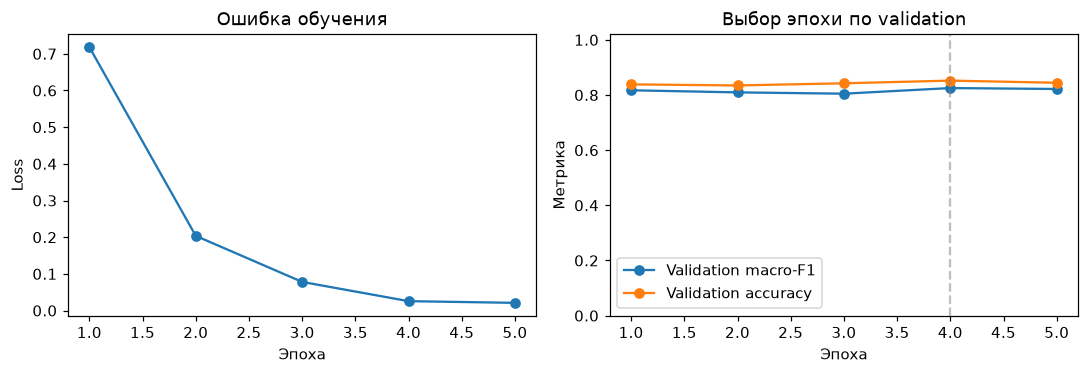

In [35]:
baseline.load_state_dict(best_state)
baseline.eval()
history = pd.DataFrame(history)
print(f'Выбрана эпоха {best_epoch}, validation macro-F1={best_score:.4f}')
display(history.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(history.epoch, history.train_loss, marker='o')
axes[0].set(xlabel='Эпоха', ylabel='Loss', title='Ошибка обучения')
axes[1].plot(history.epoch, history.val_macro_f1, marker='o', label='Validation macro-F1')
axes[1].plot(history.epoch, history.val_accuracy, marker='o', label='Validation accuracy')
axes[1].axvline(best_epoch, color='grey', linestyle='--', alpha=0.5)
axes[1].set(xlabel='Эпоха', ylabel='Метрика', ylim=(0, 1.02), title='Выбор эпохи по validation')
axes[1].legend()
plt.tight_layout()
plt.show()

## Результат на тесте
Считаю accuracy и macro-F1. В macro-F1 каждый класс влияет на результат одинаково,
что полезно при нашем дисбалансе.

In [36]:
test_true, test_pred, test_proba = evaluate(loaders['test'])
majority_class = int(frames['train'].target.value_counts().idxmax())
majority_pred = np.full_like(test_true, majority_class)
metrics = {
    'accuracy': float(accuracy_score(test_true, test_pred)),
    'macro_f1': float(f1_score(test_true, test_pred, average='macro', labels=range(5), zero_division=0)),
    'majority_accuracy': float(accuracy_score(test_true, majority_pred)),
    'majority_macro_f1': float(f1_score(test_true, majority_pred, average='macro', labels=range(5), zero_division=0)),
    'best_epoch': int(best_epoch), 'best_validation_macro_f1': best_score,
    'train_size': len(frames['train']), 'validation_size': len(frames['validation']),
    'test_size': len(test_true), 'seed': SEED,
}
display(pd.DataFrame([
    {'Модель': 'ResNet18', 'Test accuracy': metrics['accuracy'], 'Test macro-F1': metrics['macro_f1']},
    {'Модель': 'Самый частый класс train', 'Test accuracy': metrics['majority_accuracy'],
     'Test macro-F1': metrics['majority_macro_f1']},
]).set_index('Модель').round(4))

,Test accuracy,Test macro-F1
Модель,,
ResNet18,0.8427,0.8292
Самый частый класс train,0.3845,0.1111


In [37]:
report = pd.DataFrame(classification_report(test_true, test_pred, labels=range(5),
                      target_names=CLASS_NAMES, output_dict=True, zero_division=0)).T
display(report.round(4))

,precision,recall,f1-score,support
Бананы / хорошие,0.8687,0.8687,0.8687,99.0000
Бананы / плохие,0.9388,0.9293,0.9340,198.0000
Кабачки / хорошие,0.5405,0.6667,0.5970,60.0000
Кабачки / плохие,0.8387,0.7536,0.7939,138.0000
Мусор,0.9091,1.0000,0.9524,20.0000
accuracy,0.8427,0.8427,0.8427,0.8427
macro avg,0.8192,0.8437,0.8292,515.0000
weighted avg,0.8509,0.8427,0.8454,515.0000


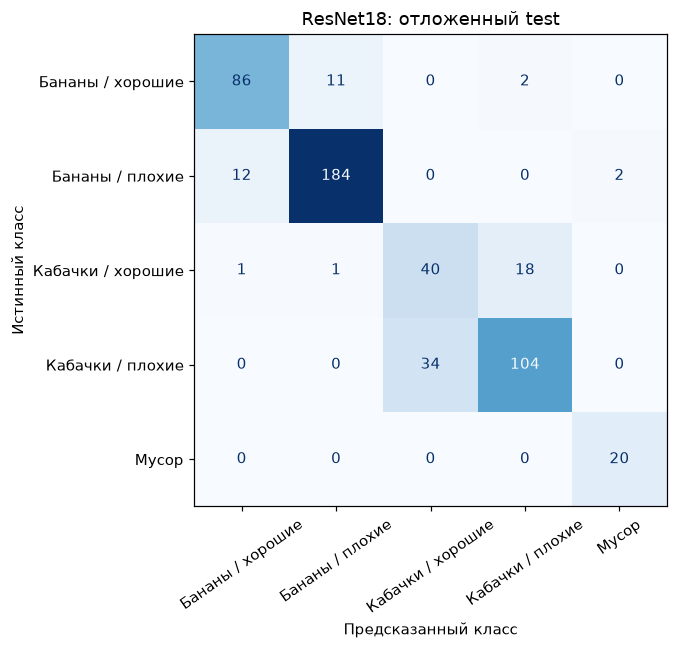

In [38]:
cm = confusion_matrix(test_true, test_pred, labels=range(5))
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, colorbar=False, cmap='Blues', xticks_rotation=35, values_format='d')
ax.set(xlabel='Предсказанный класс', ylabel='Истинный класс', title='ResNet18: отложенный test')
plt.tight_layout()
plt.show()

In [39]:
prediction_table = frames['test'][['path', 'group', 'class_name', 'target']].copy()
prediction_table['prediction'] = [CLASS_NAMES[i] for i in test_pred]
prediction_table['confidence'] = test_proba.max(axis=1)
prediction_table['correct'] = test_true == test_pred
prediction_table.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
report.to_csv(OUTPUT_DIR / 'classification_report.csv')
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')

308

Посмотрю несколько ошибок. Беру первые шесть по имени файла.

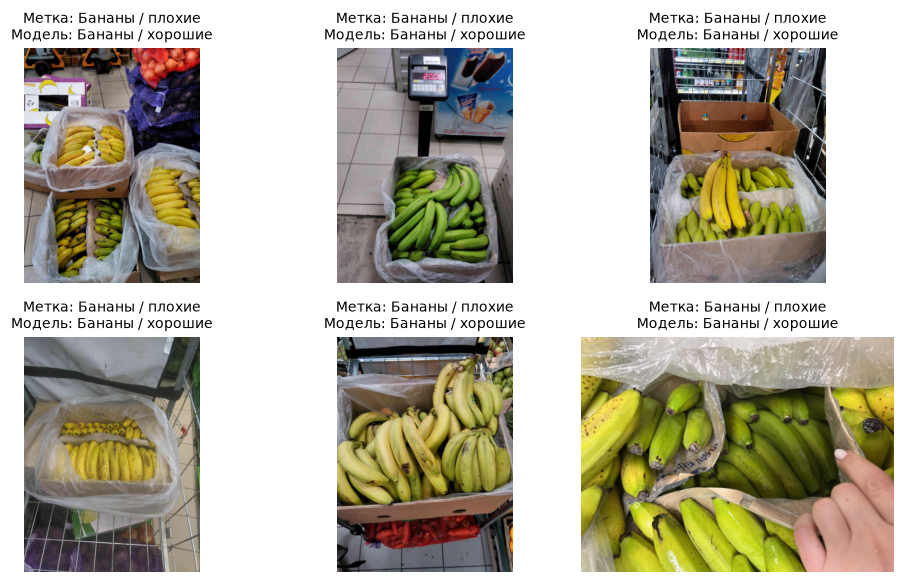

In [ ]:
mistakes = prediction_table[~prediction_table.correct].sort_values('path').head(6)
if len(mistakes):
    show_images(mistakes.path.tolist(),
        [f'Метка: {r.class_name}\nМодель: {r.prediction}' for r in mistakes.itertuples()], columns=3)

In [ ]:
checkpoint_path = OUTPUT_DIR / 'resnet18_baseline.pt'
torch.save({
    'architecture': 'resnet18', 'state_dict': best_state,
    'class_names': CLASS_NAMES, 'metrics': metrics,
    'preprocessing': {'weights': 'ResNet18_Weights.IMAGENET1K_V1',
                      'resize_size': 256, 'crop_size': 224,
                      'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]},
    'training': {'epochs': EPOCHS, 'learning_rate': 1e-4, 'weight_decay': 1e-4,
                 'batch_size': 32, 'all_layers_trainable': True, 'seed': SEED},
}, checkpoint_path)

Веса сохранены: artifacts/checkpoint2/resnet18_baseline.pt


## Выводы по модели

На тесте из 515 фотографий получил **accuracy 84.27%** и **macro-F1 0.8292**.
Если всегда отвечать самым частым классом, accuracy будет 38.45%.
То есть первая модель уже даёт заметно лучший результат.

Хуже всего получается класс «Кабачки / хорошие»: F1 — 0.597.
По матрице видно, что модель чаще путает состояние кабачков, чем сам вид товара. 
При этом, когда я сам глазами отбирал товар просмативая все фото, мне было сложно отличить
когда товар плохой а когда хороший, думаю, что у самой компании нет единого мнения на этот счет и 
в будщем лучше отказаться от автоматической разметки кабочка и оставить его для операционистов.

Лучшая эпоха по валидации — 4. К концу обучения accuracy на train почти 100%,
а на валидации около 84%. Похоже на переобучение,
поэтому оставляю лучшую эпоху, а не последнюю.